# Exploración y clasificación de gatos y perros

Este cuaderno audita el dataset local, explora su balance, integridad, dimensiones y duplicados exactos, visualiza nueve ejemplos de cada clase y genera particiones reproducibles. La red y el pipeline final están en `src/app.py`. La partición de prueba queda reservada para la evaluación final, no para tomar decisiones durante el EDA.

Imágenes válidas: 25,000
Archivos excluidos: 0
Grupos de duplicados exactos: 5 (6 copias adicionales)
Modos de color: {'RGB': 25000}
Dimensiones más frecuentes:


,dimensiones,imágenes
0,500x374,2955
1,499x375,2912
2,375x499,261
3,499x333,229
4,374x500,227
5,319x240,207
6,500x332,200
7,320x239,192
8,500x373,101
9,500x331,95


Recuento por partición y clase:


label,cat,dog
split,,
test,1875,1875
train,8750,8750
validation,1875,1875


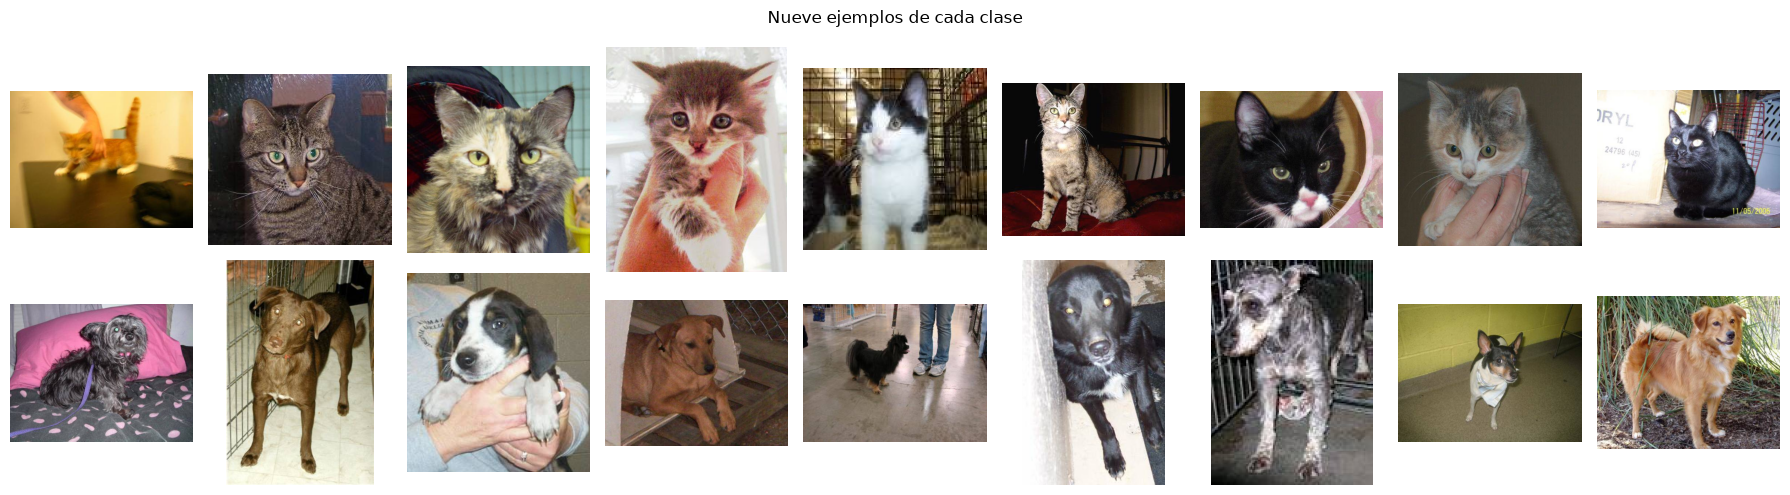

Mapa de clases: {'cat': 0, 'dog': 1}
Semilla: 42 | proporciones previstas: {'train': 0.7, 'validation': 0.15, 'test': 0.15}
Manifiesto: /workspaces/campivargas07-Tutorial-de-Clasficador-de-Imagenesmachine-learning-python-template/data/processed/splits.csv


In [ ]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd
from PIL import Image

ROOT = Path.cwd()
if not (ROOT / "src" / "app.py").exists():
    ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))
from app import DEFAULT_DATA, DEFAULT_MANIFEST, create_manifest

# Auditoría completa y particiones sin fuga entre grupos SHA-256.
audit = create_manifest(DEFAULT_DATA, DEFAULT_MANIFEST, seed=42)
print(f"Imágenes válidas: {audit['num_images_usable']:,}")
print(f"Archivos excluidos: {audit['excluded_count']}")
print(f"Grupos de duplicados exactos: {audit['duplicate_groups']} "
      f"({audit['duplicate_files_beyond_first']} copias adicionales)")
print("Modos de color:", audit["image_modes"])
print("Dimensiones más frecuentes:")
display(pd.DataFrame(audit["dimensions_top_10"], columns=["dimensiones", "imágenes"]))
print("Recuento por partición y clase:")
splits = pd.read_csv(DEFAULT_MANIFEST)
display(pd.crosstab(splits["split"], splits["label"]))

# Mosaicos 3x3 de ejemplos de cada clase (lectura directa de nueve archivos por clase).
fig, axes = plt.subplots(2, 9, figsize=(18, 5))
for row_index, label in enumerate(("cat", "dog")):
    examples = sorted(DEFAULT_DATA.glob(f"{label}.*.jpg"))[:9]
    for col_index, image_path in enumerate(examples):
        with Image.open(image_path) as image:
            axes[row_index, col_index].imshow(image.convert("RGB"))
        axes[row_index, col_index].axis("off")
        if col_index == 0:
            axes[row_index, col_index].set_ylabel(label, fontsize=13)
fig.suptitle("Nueve ejemplos de cada clase")
fig.tight_layout()
plt.show()

print("Mapa de clases:", audit["class_to_index"])
print("Semilla:", audit["seed"], "| proporciones previstas:", audit["split_ratios"])
print("Manifiesto:", audit["manifest"])


## Conclusiones

- Se auditaron **25,000 imágenes RGB válidas**, con **12,500 gatos** y **12,500 perros**; no se encontraron archivos inválidos.
- Se detectaron **5 grupos de duplicados exactos** (6 copias adicionales). Las copias de cada grupo se mantuvieron en una sola partición.
- Se generaron particiones reproducibles con semilla 42: **70% entrenamiento, 15% validación y 15% prueba**, estratificadas por clase.
- La arquitectura EfficientNetB0 y el flujo de entrenamiento están implementados en `src/app.py`. **El entrenamiento completo no se ejecutó**, por lo que todavía no hay métricas finales de prueba ni un modelo final guardado.

Para completar el experimento, instala las dependencias, ejecuta `python src/app.py train --batch-size 16 --epochs 30 --seed 42` y reporta las métricas guardadas en `models/metadata.json` únicamente después de finalizar correctamente.